# 05 · Expression — EMT-transcription-factor overlay

*(Renumbered to 05: Gate 3 = NO-GO on the branching manifold, so the branching-only `05_modules`
GO artifact is not produced (§6); this unconditional expression step follows `04_correlation`.)*

EMT-TFs gated on detectable expression, from a panel including FOXC and PRRX families (not only
Snail/Zeb/Twist). VIM excluded (mesenchymal effector, not a TF). Shown descriptively as thresholded
expressers on the grey scoped manifold (categorical overlay), on the native embedding.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
t = adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
early = tn<=np.quantile(tn,1/3); late = tn>=np.quantile(tn,2/3)
rows=[]
for j,g in enumerate(present):
    x=X[:,j]; rho,_=spearmanr(tn,x)
    rows.append((g,round((x>0).mean(),3),round(x[early].mean(),3),round(x[late].mean(),3),round(rho,3)))
df=pd.DataFrame(rows,columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
print(df.to_string(index=False))
ok=df[df.frac_expr>0.03]; tf_a=ok.iloc[0]['TF']; tf_b=ok.iloc[-1]['TF']
print(f'two most-separating detectable EMT-TFs (descriptive): {tf_a}, {tf_b}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t
 FOXC2      0.005       0.030      0.002    -0.048
 FOXC1      0.002       0.006      0.007    -0.022
TWIST2      0.002       0.000      0.000    -0.008
TWIST1      0.002       0.007      0.004    -0.002
  ZEB1      0.771       3.120      3.524     0.005
 SNAI2      0.026       0.082      0.135     0.047
 SNAI1      0.080       0.277      0.347     0.056
 PRRX2      0.012       0.003      0.064     0.066
  ZEB2      0.758       2.546      3.061     0.069
 PRRX1      0.555       1.595      2.721     0.234
two most-separating detectable EMT-TFs (descriptive): ZEB1, PRRX1


### EMT-TF expression overlay (`expression.pdf`) — descriptive categorical overlay

cells shown: {'ZEB1': 379, 'PRRX1': 273}
saved expression.pdf


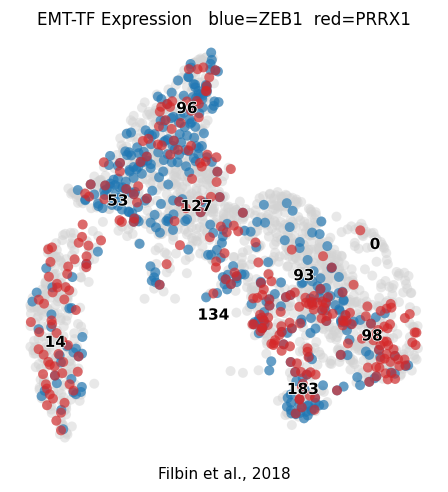

In [4]:
def vec(g):
    x=adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={g:(float(np.quantile(vec(g)[vec(g)>0],0.75)) if (vec(g)>0).any() else 0.0) for g in [tf_a,tf_b]}
sel={g:vec(g)>thr[g] for g in [tf_a,tf_b]}
order=sorted([tf_a,tf_b], key=lambda g:-int(sel[g].sum()))
colors={tf_a:'tab:blue', tf_b:'tab:red'}
fig, ax = plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata, size=170, alpha=.5, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    sc.pl.umap(adata[sel[g]].copy(), na_color=colors[g], size=170, alpha=.65, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='milestones', size=170, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title(f'EMT-TF Expression   {colors[tf_a][4:]}={tf_a}  {colors[tf_b][4:]}={tf_b}', size=11)
ax.text(.5,-.05,'Filbin et al., 2018', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
print('cells shown:', {g:int(sel[g].sum()) for g in [tf_a,tf_b]}); print('saved expression.pdf')